In [1]:
from laser import BEX
from results import PointData
# from beamsquare import get_beam_centroid

DISTANCE = 5190

In [2]:
FULL_ROTATION = 300_000
bex = BEX()

## Optimum w/ Test Data


STEP = 73000
DIVERGENCE = 22.222928709055875

0      351.348459
1      351.348459
2      351.348459
3      351.348459
4      351.348459
          ...    
595    351.348459
596    351.348459
597    351.348459
598    351.348459
599    351.348459
Length: 600, dtype: float64
156
78000


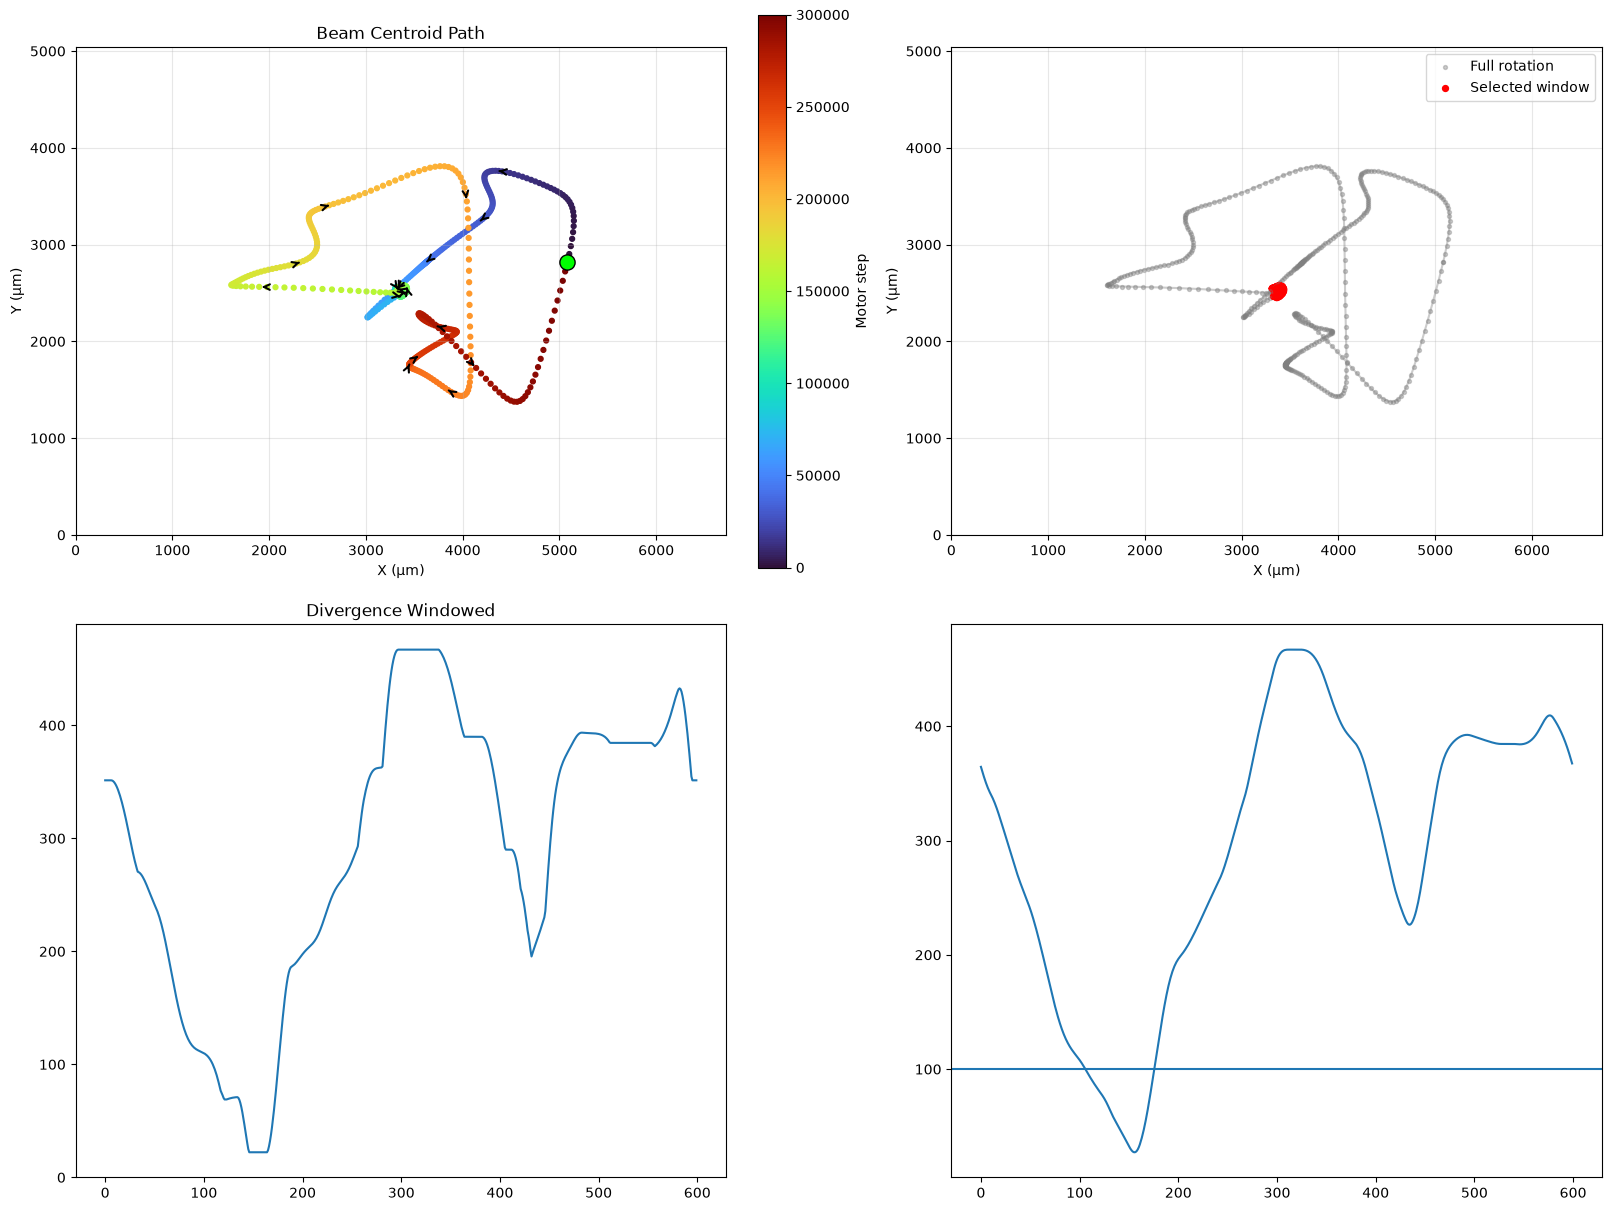

In [8]:
import matplotlib.pyplot as plt

data = PointData.from_csv(
    "../../data/ornate_beam_centroid_300000_steps_um_quiet_quarter.csv"
)

optimum_data, div_step = data.get_optimum_window(
    window_divider=4,
    distance=DISTANCE,
    full_rotation=300000
)

print(f"""
STEP = {optimum_data.step[0]}
DIVERGENCE = {optimum_data.get_total_divergence(DISTANCE)}
""")

print(div_step)
fig, axes = plt.subplots(2, 2, figsize=(16, 12), constrained_layout=True)
axes = axes.flatten()

data.plot_scatter(ax=axes[0])

data.plot_window(optimum_data, ax=axes[1])

div_step.plot(ax=axes[2], title="Divergence Windowed")



from scipy.ndimage import uniform_filter1d
import numpy as np

avg = uniform_filter1d(div_step.to_numpy(), size=30, mode="wrap")

print(np.argmin(avg))
print(data.step[np.argmin(avg)])

axes[3].plot(avg)
axes[3].axhline(100)
plt.show()

## Full Rotation & Collect Data -> PointData

In [2]:
import time

SAMPLE_INTERVAL = 500
POLL_RATE = 20 # ms
start_index = bex.get_index()
next_sample = SAMPLE_INTERVAL

x_points = []
y_points = []
steps = []



x0,y0 = get_beam_centroid()
x_points.append(x0)
y_points.append(y0)
steps.append(0)


bex.rotate_cw(FULL_ROTATION)

while next_sample <= FULL_ROTATION:

    current_index = bex.get_index()
    position = current_index - start_index

    if position >= next_sample:
        x, y = get_beam_centroid()

        x_points.append(x)
        y_points.append(y)
        steps.append(position)

        # Advance to the next interval not yet passed
        next_sample = ((position // SAMPLE_INTERVAL) + 1) * SAMPLE_INTERVAL

    time.sleep(POLL_RATE / 1000)

    

data = PointData(np.array(x_points), np.array(y_points), np.array(steps))
    

optimum_data, div_step = data.get_optimum_window()
print(F"""
STEP = {optimum_data.step[0]}
DIVERGENCE = {optimum_data.get_total_divergence(DISTANCE)}


""")
data.plot_window(optimum_data)

    

NameError: name 'bex' is not defined


STEP = 73000
DIVERGENCE = 22.18019230769231





<Axes: title={'center': 'Selected Beam Path Window'}, xlabel='X (µm)', ylabel='Y (µm)'>

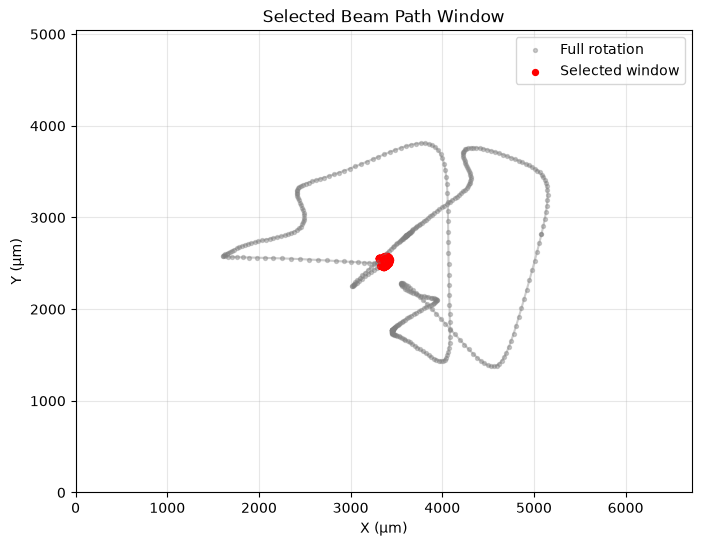

In [4]:
data = PointData.from_csv("../../data/ornate_beam_centroid_300000_steps_um_quiet_quarter.csv")

optimum_data = data.get_optimum_window()

optimum_data = data.get_optimum_window()
print(F"""
STEP = {optimum_data.step[0]}
DIVERGENCE = {optimum_data.get_total_divergence(5200)}


""")
data.plot_window(optimum_data)
